In [ ]:
# ============================================================================
# GREEN FOUNDRY TRANSITION MODEL
# NordWerk GmbH – Industrial Decarbonisation Pathways
# ============================================================================
# Baseline Year: 2025
# Projection Period: 2026–2035
# Author: Chisom Fortune Chinedu-Onuoha
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ============================================================================
# 1. BASELINE DATA (2025)
# ============================================================================

# Energy Consumption
elec_consumption = 1_298_400  # kWh/year
gas_consumption = 4_500_000    # kWh/year

# Emission Factors
grid_ef = 0.344   # kg CO2/kWh (UBA 2025)
gas_ef = 0.201    # kg CO2/kWh (DEFRA 2025)

# Energy Prices
elec_price = 0.183  # €/kWh
gas_price = 0.082   # €/kWh

# Baseline Emissions
scope2_baseline = (elec_consumption * grid_ef) / 1000  # t CO2e
scope1_baseline = (gas_consumption * gas_ef) / 1000    # t CO2e
total_baseline = scope2_baseline + scope1_baseline     # t CO2e

# Baseline Energy Costs
elec_cost_baseline = elec_consumption * elec_price  # €
gas_cost_baseline = gas_consumption * gas_price     # €
total_cost_baseline = elec_cost_baseline + gas_cost_baseline  # €

# Target
target_reduction = 0.40
target_emissions = total_baseline * (1 - target_reduction)

print("=" * 70)
print("NORDWERK GMBH – 2025 BASELINE")
print("=" * 70)
print(f"Scope 1 Emissions: {scope1_baseline:.3f} t CO2e")
print(f"Scope 2 Emissions: {scope2_baseline:.3f} t CO2e")
print(f"Total Baseline Emissions: {total_baseline:.3f} t CO2e")
print(f"Total Baseline Energy Cost: €{total_cost_baseline:,.3f}")
print(f"Target Emissions (40% reduction): {target_emissions:.3f} t CO2e")

NORDWERK GMBH – 2025 BASELINE
Scope 1 Emissions: 904.500 t CO2e
Scope 2 Emissions: 446.650 t CO2e
Total Baseline Emissions: 1351.150 t CO2e
Total Baseline Energy Cost: €606,607.200
Target Emissions (40% reduction): 810.690 t CO2e


In [ ]:
# ============================================================================
# 2. SCENARIO MODELLING FUNCTIONS
# ============================================================================

def scenario_BAU(years=10, production_growth=0.01, grid_decarb=0.025):
    """
    Scenario A: Cautious Observer (Business As Usual)
    - Production grows 1% per year
    - Grid decarbonizes 2.5% per year
    - Gas price escalates 2% per year
    - No capital investments
    """
    results = []
    for i in range(years):
        year = 2026 + i
        # Adjust energy for production growth
        elec = elec_consumption * (1 + production_growth) ** i
        gas = gas_consumption * (1 + production_growth) ** i
        # Adjust grid emission factor for decarbonization
        grid_factor = grid_ef * (1 - grid_decarb) ** i
        # Calculate emissions
        s2 = (elec * grid_factor) / 1000
        s1 = (gas * gas_ef) / 1000
        total = s1 + s2
        results.append({'Year': year, 'Total_tCO2e': total, 'Scope1': s1, 'Scope2': s2})
    return pd.DataFrame(results)


def scenario_LowCost(years=10, production_growth=0.01, grid_decarb=0.025, efficiency_gain=0.10):
    """
    Scenario B: Efficiency Seeker (Low-Cost)
    - 10% one-time efficiency gain by 2027
    - Production grows 1% per year
    - Grid decarbonizes 2.5% per year
    - No major capital investments
    """
    results = []
    for i in range(years):
        year = 2026 + i
        # Apply efficiency gain progressively (reaches full effect by 2027)
        eff_factor = 1.0
        if i >= 2:
            eff_factor = 1.0 - efficiency_gain
        # Adjust energy for production growth and efficiency
        elec = elec_consumption * (1 + production_growth) ** i * eff_factor
        gas = gas_consumption * (1 + production_growth) ** i * eff_factor
        # Adjust grid emission factor
        grid_factor = grid_ef * (1 - grid_decarb) ** i
        # Calculate emissions
        s2 = (elec * grid_factor) / 1000
        s1 = (gas * gas_ef) / 1000
        total = s1 + s2
        results.append({'Year': year, 'Total_tCO2e': total, 'Scope1': s1, 'Scope2': s2})
    return pd.DataFrame(results)


def scenario_Capital(years=10, production_growth=0.01, grid_decarb=0.025):
    """
    Scenario C: Green Foundry (Capital Investment) – CORRECTED
    - Solar PV (1.0 MWp) installed by 2027
    - Electric furnace (3,200,000 kWh electricity) replaces gas furnace (4,000,000 kWh gas) by 2029
    - Heat pump (500 kW, COP 4) replaces 500,000 kWh gas for heating by 2028
    - Production grows 1% per year
    - Grid decarbonizes 2.5% per year
    """
    results = []
    for i in range(years):
        year = 2026 + i

        # Base electricity and gas (before capital measures)
        base_elec = elec_consumption * (1 + production_growth) ** i
        base_gas = gas_consumption * (1 + production_growth) ** i

        # --- Solar PV Generation ---
        # 1.0 MWp installed by 2027, ramps over 2 years
        solar_generation = 0
        if i >= 1:  # 2027 onwards
            solar_capacity = 1_000  # kWp
            solar_yield = 900  # kWh/kWp
            solar_generation = solar_capacity * solar_yield  # 900,000 kWh/year
            # Ramp up over 2 years
            ramp_factor = min(1.0, (i) / 2)
            solar_generation = solar_generation * ramp_factor

        # --- Electric Furnace (replaces gas furnace) ---
        # Gas furnace: 4,000,000 kWh gas. Gas efficiency: 80%. Electric efficiency: 95%.
        # Electricity needed = 4,000,000 * 0.80 / 0.95 = 3,368,421 kWh
        furnace_elec_needed = 0
        furnace_gas_reduction = 0
        if i >= 3:  # 2029 onwards
            furnace_elec_needed = 4_000_000 * 0.80 / 0.95  # 3,368,421 kWh
            furnace_gas_reduction = 4_000_000  # kWh gas
            # Ramp over 2 years
            ramp_factor = min(1.0, (i - 2) / 2)
            furnace_elec_needed = furnace_elec_needed * ramp_factor
            furnace_gas_reduction = furnace_gas_reduction * ramp_factor

        # --- Heat Pump (replaces gas heating) ---
        # Replaces 500,000 kWh gas. COP = 4. Electricity needed = 500,000 / 4 = 125,000 kWh
        heatpump_elec_needed = 0
        heatpump_gas_reduction = 0
        if i >= 2:  # 2028 onwards
            heatpump_elec_needed = 500_000 / 4  # 125,000 kWh
            heatpump_gas_reduction = 500_000  # kWh gas
            # Ramp over 2 years
            ramp_factor = min(1.0, (i - 1) / 2)
            heatpump_elec_needed = heatpump_elec_needed * ramp_factor
            heatpump_gas_reduction = heatpump_gas_reduction * ramp_factor

        # --- Net Electricity ---
        total_elec_demand = base_elec + furnace_elec_needed + heatpump_elec_needed
        net_grid_elec = max(0, total_elec_demand - solar_generation)

        # --- Net Gas ---
        net_gas = max(0, base_gas - furnace_gas_reduction - heatpump_gas_reduction)

        # --- Grid Emission Factor ---
        grid_factor = grid_ef * (1 - grid_decarb) ** i

        # --- Calculate Emissions ---
        s2 = (net_grid_elec * grid_factor) / 1000
        s1 = (net_gas * gas_ef) / 1000
        total = s1 + s2

        results.append({
            'Year': year,
            'Total_tCO2e': total,
            'Scope1': s1,
            'Scope2': s2,
            'Net_Electricity': net_grid_elec,
            'Net_Gas': net_gas,
            'Solar_Generation': solar_generation
        })

    return pd.DataFrame(results)

In [ ]:
# ============================================================================
# 3. RUN SCENARIOS
# ============================================================================

# Run all three scenarios
bau = scenario_BAU(years=10)
lowcost = scenario_LowCost(years=10)
capital = scenario_Capital(years=10)

# Display results
print("\n" + "=" * 70)
print("SCENARIO RESULTS (2026–2035)")
print("=" * 70)
print("\n--- Scenario A: BAU ---")
print(bau[['Year', 'Total_tCO2e']].round(3).to_string(index=False))
print("\n--- Scenario B: Low-Cost ---")
print(lowcost[['Year', 'Total_tCO2e']].round(3).to_string(index=False))
print("\n--- Scenario C: Capital ---")
print(capital[['Year', 'Total_tCO2e']].round(3).to_string(index=False))

# Summary
bau_2035 = bau['Total_tCO2e'].iloc[-1]
lowcost_2035 = lowcost['Total_tCO2e'].iloc[-1]
capital_2035 = capital['Total_tCO2e'].iloc[-1]

print("\n" + "=" * 70)
print("SUMMARY (2035)")
print("=" * 70)
print(f"Baseline (2025): {total_baseline:.3f} t CO2e")
print(f"Target (40% reduction): {target_emissions:.3f} t CO2e")
print(f"BAU (2035): {bau_2035:.3f} t CO2e ({(bau_2035 - total_baseline) / total_baseline * 100:+.3f}%)")
print(f"Low-Cost (2035): {lowcost_2035:.3f} t CO2e ({(lowcost_2035 - total_baseline) / total_baseline * 100:+.3f}%)")
print(f"Capital (2035): {capital_2035:.3f} t CO2e ({(capital_2035 - total_baseline) / total_baseline * 100:+.3f}%)")


SCENARIO RESULTS (2026–2035)

--- Scenario A: BAU ---
 Year  Total_tCO2e
 2026     1351.150
 2027     1353.383
 2028     1355.811
 2029     1358.433
 2030     1361.247
 2031     1364.254
 2032     1367.453
 2033     1370.843
 2034     1374.424
 2035     1378.195

--- Scenario B: Low-Cost ---
 Year  Total_tCO2e
 2026     1351.150
 2027     1353.383
 2028     1220.230
 2029     1222.589
 2030     1225.123
 2031     1227.829
 2032     1230.708
 2033     1233.759
 2034     1236.981
 2035     1240.375

--- Scenario C: Capital ---
 Year  Total_tCO2e
 2026     1351.150
 2027     1202.453
 2028     1031.686
 2029     1145.825
 2030     1262.960
 2031     1245.812
 2032     1229.359
 2033     1213.589
 2034     1198.489
 2035     1184.046

SUMMARY (2035)
Baseline (2025): 1351.150 t CO2e
Target (40% reduction): 810.690 t CO2e
BAU (2035): 1378.195 t CO2e (+2.002%)
Low-Cost (2035): 1240.375 t CO2e (-8.199%)
Capital (2035): 1184.046 t CO2e (-12.368%)


In [ ]:
# ============================================================================
# GAP-CLOSING MEASURES FOR THE CAPITAL SCENARIO
# ============================================================================

def scenario_Capital_with_gap_closing(years=10, production_growth=0.01, grid_decarb=0.025):
    """
    Scenario C: Green Foundry + Gap-Closing Measures
    - Solar PV expanded from 1.0 MWp to 2.5 MWp
    - Battery storage (1 MWh)
    - Wind PPA for 500,000 kWh/year
    - Green hydrogen injection (10% of remaining gas)
    """
    results = []
    for i in range(years):
        year = 2026 + i

        # --- Base Energy ---
        base_elec = elec_consumption * (1 + production_growth) ** i
        base_gas = gas_consumption * (1 + production_growth) ** i

        # --- Solar PV Generation (1.0 MWp from 2027, expanded to 2.5 MWp from 2029) ---
        solar_capacity = 1_000  # kWp (initial)
        if i >= 3:  # 2029 onwards
            solar_capacity = 2_500  # kWp (expanded)

        solar_generation = 0
        if i >= 1:  # 2027 onwards
            solar_yield = 900  # kWh/kWp
            solar_generation = solar_capacity * solar_yield
            ramp_factor = min(1.0, i / 2)
            solar_generation = solar_generation * ramp_factor

        # --- Battery Storage (from 2029) ---
        battery_boost = 0
        if i >= 3:
            battery_boost = 25_000  # kWh/year additional self-consumption
            ramp_factor = min(1.0, (i - 2) / 2)
            battery_boost = battery_boost * ramp_factor

        # --- Wind PPA (from 2028) ---
        wind_ppa = 0
        if i >= 2:
            wind_ppa = 500_000  # kWh/year
            ramp_factor = min(1.0, (i - 1) / 2)
            wind_ppa = wind_ppa * ramp_factor

        # --- Electric Furnace ---
        furnace_elec_needed = 0
        furnace_gas_reduction = 0
        if i >= 3:
            furnace_elec_needed = 4_000_000 * 0.80 / 0.95  # 3,368,421 kWh
            furnace_gas_reduction = 4_000_000
            ramp_factor = min(1.0, (i - 2) / 2)
            furnace_elec_needed = furnace_elec_needed * ramp_factor
            furnace_gas_reduction = furnace_gas_reduction * ramp_factor

        # --- Heat Pump ---
        heatpump_elec_needed = 0
        heatpump_gas_reduction = 0
        if i >= 2:
            heatpump_elec_needed = 500_000 / 4  # 125,000 kWh
            heatpump_gas_reduction = 500_000
            ramp_factor = min(1.0, (i - 1) / 2)
            heatpump_elec_needed = heatpump_elec_needed * ramp_factor
            heatpump_gas_reduction = heatpump_gas_reduction * ramp_factor

        # --- Net Electricity ---
        total_elec_demand = base_elec + furnace_elec_needed + heatpump_elec_needed
        net_grid_elec = max(0, total_elec_demand - solar_generation - battery_boost - wind_ppa)

        # --- Net Gas (with green hydrogen injection from 2030) ---
        net_gas = max(0, base_gas - furnace_gas_reduction - heatpump_gas_reduction)
        if i >= 4:  # 2030 onwards
            hydrogen_injection = 0.10  # 10% of remaining gas replaced by green hydrogen
            net_gas = net_gas * (1 - hydrogen_injection)

        # --- Grid Emission Factor ---
        grid_factor = grid_ef * (1 - grid_decarb) ** i

        # --- Calculate Emissions ---
        s2 = (net_grid_elec * grid_factor) / 1000
        s1 = (net_gas * gas_ef) / 1000
        total = s1 + s2

        results.append({
            'Year': year,
            'Total_tCO2e': total,
            'Scope1': s1,
            'Scope2': s2,
            'Net_Electricity': net_grid_elec,
            'Net_Gas': net_gas,
            'Solar_Generation': solar_generation,
            'Wind_PPA': wind_ppa
        })

    return pd.DataFrame(results)

# Run the updated scenario
capital_gap = scenario_Capital_with_gap_closing(years=10)

print("=" * 70)
print("CAPITAL SCENARIO WITH GAP-CLOSING MEASURES")
print("=" * 70)
print(capital_gap[['Year', 'Total_tCO2e', 'Scope1', 'Scope2']].round(3).to_string(index=False))

# Summary
capital_gap_2035 = capital_gap['Total_tCO2e'].iloc[-1]
print(f"\nCapital + Gap Closing (2035): {capital_gap_2035:.3f} tCO2e")
print(f"Reduction vs 2025: {(capital_gap_2035 - total_baseline) / total_baseline * 100:.3f}%")
print(f"Target: {target_emissions:.3f} tCO2e")
print(f"Gap Remaining: {capital_gap_2035 - target_emissions:.3f} tCO2e")

CAPITAL SCENARIO WITH GAP-CLOSING MEASURES
 Year  Total_tCO2e  Scope1  Scope2
 2026     1351.150 904.500 446.650
 2027     1202.453 913.545 288.908
 2028      949.932 872.430  77.502
 2029      551.986 429.407 122.579
 2030      676.409  33.054 643.355
 2031      672.892  41.525 631.367
 2032      669.696  50.080 619.615
 2033      666.818  58.722 608.096
 2034      664.254  67.450 596.805
 2035      662.000  76.264 585.735

Capital + Gap Closing (2035): 662.000 tCO2e
Reduction vs 2025: -51.005%
Target: 810.690 tCO2e
Gap Remaining: -148.690 tCO2e


MONTE CARLO SIMULATION – GREEN FOUNDRY TRANSITION MODEL
Running 500 iterations...

MONTE CARLO RESULTS (2035)
Target Emissions (40% reduction): 810.690 tCO2e
Mean Emissions: 675.496 tCO2e
Median Emissions: 647.408 tCO2e
5th Percentile (Best Case): 450.414 tCO2e
95th Percentile (Worst Case): 982.396 tCO2e
Probability of Achieving Target: 81.200%


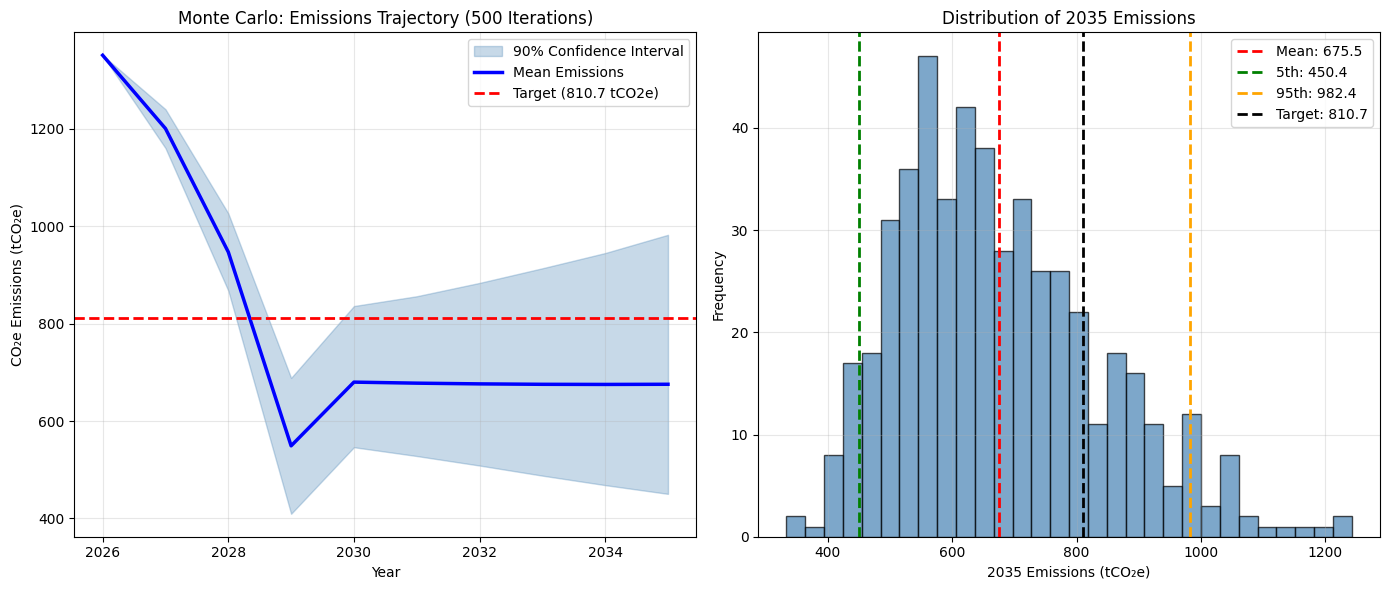


✅ Monte Carlo simulation complete. Chart saved as 'monte_carlo_results.png'


In [ ]:
# ============================================================================
# MONTE CARLO SIMULATION FOR THE GREEN FOUNDRY TRANSITION MODEL
# NordWerk GmbH – 500 Iterations
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ============================================================================
# 1. BASELINE (2025) – FIXED VALUES
# ============================================================================
elec_consumption = 1_298_400
gas_consumption = 4_500_000
grid_ef = 0.344
gas_ef = 0.201
elec_price = 0.183
gas_price = 0.082

scope2_baseline = (elec_consumption * grid_ef) / 1000
scope1_baseline = (gas_consumption * gas_ef) / 1000
total_baseline = scope2_baseline + scope1_baseline
target_reduction = 0.40
target_emissions = total_baseline * (1 - target_reduction)

# ============================================================================
# 2. MONTE CARLO SIMULATION ENGINE
# ============================================================================

def monte_carlo_green_foundry(iterations=500, years=10):
    """
    Monte Carlo simulation for NordWerk GmbH.
    Randomly samples from probability distributions for key parameters.
    Returns an array of shape (iterations, years).
    """
    # --- Probability Distributions ---
    prod_growth_dist = stats.norm(0.01, 0.015)        # Mean 1%, SD 1.5%
    grid_decarb_dist = stats.norm(0.025, 0.010)       # Mean 2.5%, SD 1%
    elec_price_dist = stats.norm(0.183, 0.030)        # Mean €0.183, SD €0.03
    gas_price_dist = stats.norm(0.082, 0.015)         # Mean €0.082, SD €0.015
    solar_yield_dist = stats.norm(900, 75)            # Mean 900 kWh/kWp, SD 75
    heatpump_cop_dist = stats.norm(4.0, 0.5)          # Mean COP 4.0, SD 0.5

    all_results = []

    for _ in range(iterations):
        # Sample uncertain parameters
        prod_growth = prod_growth_dist.rvs()
        grid_decarb = grid_decarb_dist.rvs()
        elec_price = elec_price_dist.rvs()
        gas_price = gas_price_dist.rvs()
        solar_yield = solar_yield_dist.rvs()
        heatpump_cop = heatpump_cop_dist.rvs()

        emissions_series = []

        for i in range(years):
            year = 2026 + i

            # --- Base Energy Demand ---
            base_elec = elec_consumption * (1 + prod_growth) ** i
            base_gas = gas_consumption * (1 + prod_growth) ** i

            # --- Solar PV (1.0 MWp from 2027, expanded to 2.5 MWp from 2029) ---
            solar_capacity = 1_000
            if i >= 3:
                solar_capacity = 2_500
            solar_generation = 0
            if i >= 1:
                solar_generation = solar_capacity * solar_yield
                ramp_factor = min(1.0, i / 2)
                solar_generation = solar_generation * ramp_factor

            # --- Battery Storage (from 2029) ---
            battery_boost = 0
            if i >= 3:
                battery_boost = 25_000 * min(1.0, (i - 2) / 2)

            # --- Wind PPA (from 2028) ---
            wind_ppa = 0
            if i >= 2:
                wind_ppa = 500_000 * min(1.0, (i - 1) / 2)

            # --- Electric Furnace (from 2029) ---
            furnace_elec_needed = 0
            furnace_gas_reduction = 0
            if i >= 3:
                furnace_elec_needed = 4_000_000 * 0.80 / 0.95
                furnace_gas_reduction = 4_000_000
                ramp_factor = min(1.0, (i - 2) / 2)
                furnace_elec_needed = furnace_elec_needed * ramp_factor
                furnace_gas_reduction = furnace_gas_reduction * ramp_factor

            # --- Heat Pump (from 2028, COP sampled from distribution) ---
            heatpump_elec_needed = 0
            heatpump_gas_reduction = 0
            if i >= 2:
                heatpump_elec_needed = 500_000 / heatpump_cop
                heatpump_gas_reduction = 500_000
                ramp_factor = min(1.0, (i - 1) / 2)
                heatpump_elec_needed = heatpump_elec_needed * ramp_factor
                heatpump_gas_reduction = heatpump_gas_reduction * ramp_factor

            # --- Net Electricity ---
            total_elec_demand = base_elec + furnace_elec_needed + heatpump_elec_needed
            net_grid_elec = max(0, total_elec_demand - solar_generation - battery_boost - wind_ppa)

            # --- Net Gas (with green hydrogen injection from 2030) ---
            net_gas = max(0, base_gas - furnace_gas_reduction - heatpump_gas_reduction)
            if i >= 4:
                net_gas = net_gas * 0.90  # 10% green hydrogen injection

            # --- Grid Emission Factor ---
            grid_factor = grid_ef * (1 - grid_decarb) ** i

            # --- Calculate Emissions ---
            s2 = (net_grid_elec * grid_factor) / 1000
            s1 = (net_gas * gas_ef) / 1000
            total = s1 + s2

            emissions_series.append(total)

        all_results.append(emissions_series)

    return np.array(all_results)


# ============================================================================
# 3. RUN MONTE CARLO SIMULATION
# ============================================================================

print("=" * 70)
print("MONTE CARLO SIMULATION – GREEN FOUNDRY TRANSITION MODEL")
print("=" * 70)
print("Running 500 iterations...")

mc_results = monte_carlo_green_foundry(iterations=500, years=10)

# ============================================================================
# 4. RESULTS SUMMARY
# ============================================================================

final_emissions = mc_results[:, -1]  # 2035 emissions for all iterations

mean_2035 = np.mean(final_emissions)
median_2035 = np.median(final_emissions)
p5_2035 = np.percentile(final_emissions, 5)
p95_2035 = np.percentile(final_emissions, 95)
prob_target = np.mean(final_emissions < target_emissions) * 100

print("\n" + "=" * 70)
print("MONTE CARLO RESULTS (2035)")
print("=" * 70)
print(f"Target Emissions (40% reduction): {target_emissions:.3f} tCO2e")
print(f"Mean Emissions: {mean_2035:.3f} tCO2e")
print(f"Median Emissions: {median_2035:.3f} tCO2e")
print(f"5th Percentile (Best Case): {p5_2035:.3f} tCO2e")
print(f"95th Percentile (Worst Case): {p95_2035:.3f} tCO2e")
print(f"Probability of Achieving Target: {prob_target:.3f}%")

# ============================================================================
# 5. VISUALIZATION
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Plot 1: Confidence Intervals Over Time ---
ax = axes[0]
years_range = [2026 + i for i in range(10)]
mean_series = np.mean(mc_results, axis=0)
p5_series = np.percentile(mc_results, 5, axis=0)
p95_series = np.percentile(mc_results, 95, axis=0)

ax.fill_between(years_range, p5_series, p95_series, alpha=0.3, color='steelblue', label='90% Confidence Interval')
ax.plot(years_range, mean_series, 'b-', linewidth=2.5, label='Mean Emissions')
ax.axhline(y=target_emissions, color='red', linestyle='--', linewidth=2, label=f'Target ({target_emissions:.1f} tCO2e)')

ax.set_xlabel('Year')
ax.set_ylabel('CO₂e Emissions (tCO₂e)')
ax.set_title('Monte Carlo: Emissions Trajectory (500 Iterations)')
ax.legend()
ax.grid(True, alpha=0.3)

# --- Plot 2: Distribution of 2035 Emissions ---
ax = axes[1]
ax.hist(final_emissions, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
ax.axvline(mean_2035, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_2035:.1f}')
ax.axvline(p5_2035, color='green', linestyle='dashed', linewidth=2, label=f'5th: {p5_2035:.1f}')
ax.axvline(p95_2035, color='orange', linestyle='dashed', linewidth=2, label=f'95th: {p95_2035:.1f}')
ax.axvline(target_emissions, color='black', linestyle='dashed', linewidth=2, label=f'Target: {target_emissions:.1f}')

ax.set_xlabel('2035 Emissions (tCO₂e)')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of 2035 Emissions')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('monte_carlo_results.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Monte Carlo simulation complete. Chart saved as 'monte_carlo_results.png'")